## 0. Local setup

This notebook originally ran on Kaggle (`/kaggle/input`, `/kaggle/working`).
It's now configured to run locally:

- Put `Train.csv`, `Test.csv`, and (optionally) `Validation.csv` in a
  `./data` folder next to this notebook (any subfolder nesting is fine —
  files are found by name).
- Outputs (results CSV, figures) are written to `./output`.
- Run the cell below once to install dependencies that aren't in a
  typical local Python environment.

In [1]:
# Run once to install dependencies (skip if already installed).
# Uncomment the line below if running in a fresh environment:

# %pip install -q numpy pandas
#  matplotlib scikit-learn xgboost tensorflow gensim transformers lime shap

import os
os.makedirs("./data", exist_ok=True)
os.makedirs("./output", exist_ok=True)
print("data/ and output/ folders ready. Place Train.csv / Validation.csv / Test.csv in ./data")

data/ and output/ folders ready. Place Train.csv / Validation.csv / Test.csv in ./data


# SQL Injection Detection — Extended Feature Extraction & Model Comparison Pipeline



In [2]:
import os

# Longer timeouts for Hugging Face Hub calls -- default timeouts are short
# and flaky wifi/VPN connections can trip them even when the actual
# download would have succeeded a moment later.
os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "60")
os.environ.setdefault("HF_HUB_ETAG_TIMEOUT", "30")

import re
import json
import glob
import time
import random
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cycler

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

try:
    from xgboost import XGBClassifier

    HAS_XGB = True
except ImportError:
    HAS_XGB = False

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    Conv1D,
    GlobalMaxPooling1D,
    Dense,
    Dropout,
    Bidirectional,
    LSTM,
)
from tensorflow.keras.callbacks import EarlyStopping

from gensim.models import Word2Vec

# Hugging Face transformers are imported lazily only when BERT/RoBERTa tokenizers are enabled.

## 1. Reproducibility, timing, & plotting setup

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PIPELINE_START = time.time()
TECHNIQUE_TIMES = {}  # technique -> seconds, filled in during orchestration


def elapsed_since(t0):
    return round(time.time() - t0, 1)


def fmt_minutes(seconds):
    return f"{seconds / 60:.1f} min"


# Set reproducible plotting defaults; individual figures may override colors.
mpl.rcParams["image.cmap"] = "gray"
mpl.rcParams["axes.prop_cycle"] = cycler(
    color=["0.05", "0.25", "0.4", "0.55", "0.7", "0.85"]
)
mpl.rcParams["font.size"] = 10
mpl.rcParams["axes.edgecolor"] = "black"
mpl.rcParams["figure.facecolor"] = "white"
mpl.rcParams["axes.facecolor"] = "white"



def save_figure(fig, name, outdir="./output/figures"):
    """Save a figure, guaranteeing the output directory exists."""
    os.makedirs(outdir, exist_ok=True)
    path = os.path.join(outdir, f"{name}.png")
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved figure: {path}")
    return path

## 2. Config

**`FAST_MODE`**: set to `True` first to confirm the whole pipeline runs
end-to-end in ~5–10 minutes on a small subsample before committing to the
full multi-hour run. It shrinks the training sample, uses a 2-fold instead
of 5-fold CV, and trims deep-learning epochs.

In [4]:
FAST_MODE = False  # <-- flip to True for a quick sanity-check run first

CONFIG = dict(
    # Local run: put Train.csv / Validation.csv / Test.csv (or a nested
    # folder containing them) under ./data. Auto-detected by filename so
    # the exact nesting doesn't matter.
    DATA_DIR="./data",
    OUTPUT_DIR="./output",
    TEXT_COL_CANDIDATES=["Query", "query", "text", "Sentence", "statement"],
    LABEL_COL_CANDIDATES=["Label", "label", "target", "Class"],
    VAL_FALLBACK_SIZE=0.10,  # only used if no Validation.csv is found
    N_SPLITS=2 if FAST_MODE else 5,  # Stratified K-Fold for model tuning
    MAX_SEQ_LEN=145,  # kept identical to the original paper for comparability
    RANDOM_STATE=SEED,
    TFIDF_WORD_MAX_FEATURES=5000,
    WORD2VEC_PARAMS=dict(vector_size=100, window=5, min_count=1, sg=0, seed=SEED),  # sg=0 -> CBOW
    TOKENIZER_VOCAB=10000,
    RUN_TRANSFORMER_TOKENIZERS=True,   # BERT / RoBERTa tokenizers
    DEEP_EPOCHS=2 if FAST_MODE else 10,
    FAST_MODE=FAST_MODE,
    FAST_MODE_TRAIN_SAMPLE=4000,
    FAST_MODE_EVAL_SAMPLE=800,
    RESULTS_CSV=os.path.join("./output", "results_extended.csv"),
)
os.makedirs(CONFIG["OUTPUT_DIR"], exist_ok=True)

## 3. Load & preprocess data
Loads your dataset's own `Train.csv` / `Validation.csv` / `Test.csv` split
(auto-detected by filename under `./data`). Mirrors the paper's
preprocessing (lowercase, collapse whitespace, drop duplicates) and adds a
cross-split leakage guard so no row appears in more than one split.

In [5]:
def find_split_files(data_dir):
    all_csvs = glob.glob(os.path.join(data_dir, "**", "*.csv"), recursive=True)
    if not all_csvs:
        raise FileNotFoundError(
            f"No CSV found under {data_dir}. Add the SQL Injection dataset "
            "via 'Add Input' first."
        )

    def match(keyword):
        cands = [p for p in all_csvs if keyword in os.path.basename(p).lower()]
        return cands[0] if cands else None

    train_path = match("train")
    test_path = match("test")
    val_path = match("valid")  # matches both "valid.csv" and "validation.csv"

    if not (train_path and test_path):
        raise FileNotFoundError(
            "Could not find Train.csv / Test.csv under "
            f"{data_dir}. Files seen: {all_csvs}"
        )
    print(f"Found train file:      {train_path}")
    print(f"Found test file:       {test_path}")
    print(f"Found validation file: {val_path if val_path else '(none — will carve one out of train)'}")
    return train_path, val_path, test_path


def _read_csv_robust(path):
    """Try the fast C parser first; fall back to the more tolerant python
    engine (and skip unparsable rows) if malformed rows break tokenization."""
    try:
        return pd.read_csv(path)
    except pd.errors.ParserError as e:
        print(f"  [warn] {path}: C parser failed ({e}); "
              f"retrying with engine='python', on_bad_lines='skip'")
        return pd.read_csv(path, engine="python", on_bad_lines="skip")


def _clean_split(raw_df, cfg, split_name):
    text_col = next((c for c in cfg["TEXT_COL_CANDIDATES"] if c in raw_df.columns), None)
    label_col = next((c for c in cfg["LABEL_COL_CANDIDATES"] if c in raw_df.columns), None)
    if text_col is None or label_col is None:
        raise ValueError(
            f"[{split_name}] Could not find text/label columns. "
            f"Columns present: {list(raw_df.columns)}"
        )
    df = raw_df[[text_col, label_col]].rename(columns={text_col: "text", label_col: "label"})
    df = df.dropna(subset=["text", "label"])
    df["text"] = df["text"].astype(str).str.lower()
    df["text"] = df["text"].apply(lambda s: re.sub(r"\s+", " ", s).strip())
    df["label"] = df["label"].astype(int)

    before = len(df)
    df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)
    print(f"  [{split_name}] removed {before - len(df)} in-split duplicates -> {len(df)} rows")
    return df


def load_and_preprocess_data(cfg):
    train_path, val_path, test_path = find_split_files(cfg["DATA_DIR"])

    train_df = _clean_split(_read_csv_robust(train_path), cfg, "train")
    test_df = _clean_split(_read_csv_robust(test_path), cfg, "test")
    val_df = _clean_split(_read_csv_robust(val_path), cfg, "validation") if val_path else None

    # --- Leakage guard: no row should appear in more than one split ---
    train_texts = set(train_df["text"])
    before = len(test_df)
    test_df = test_df[~test_df["text"].isin(train_texts)].reset_index(drop=True)
    print(f"  [test] removed {before - len(test_df)} rows overlapping with train")

    if val_df is not None:
        before = len(val_df)
        val_df = val_df[~val_df["text"].isin(train_texts)].reset_index(drop=True)
        test_texts = set(test_df["text"])
        before2 = len(val_df)
        val_df = val_df[~val_df["text"].isin(test_texts)].reset_index(drop=True)
        print(f"  [validation] removed {before - before2} rows overlapping with train, "
              f"{before2 - len(val_df)} overlapping with test")

    for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]:
        if d is not None:
            print(f"{name} label distribution:\n{d['label'].value_counts().rename('count')}")

    return train_df, val_df, test_df


train_df, val_df, test_df = load_and_preprocess_data(CONFIG)

X_train_text, y_train = train_df["text"].values, train_df["label"].values
X_test_text, y_test = test_df["text"].values, test_df["label"].values

if val_df is not None and len(val_df) > 0:
    X_val_text, y_val = val_df["text"].values, val_df["label"].values
else:
    print("No Validation.csv found — carving a validation split out of train instead.")
    X_train_text, X_val_text, y_train, y_val = train_test_split(
        X_train_text, y_train,
        test_size=CONFIG["VAL_FALLBACK_SIZE"],
        stratify=y_train,
        random_state=CONFIG["RANDOM_STATE"],
    )

if CONFIG["FAST_MODE"]:
    rng = np.random.RandomState(SEED)

    def _subsample(X, y, n):
        n = min(n, len(X))
        idx = rng.choice(len(X), size=n, replace=False)
        return X[idx], y[idx]

    X_train_text, y_train = _subsample(X_train_text, y_train, CONFIG["FAST_MODE_TRAIN_SAMPLE"])
    X_val_text, y_val = _subsample(X_val_text, y_val, CONFIG["FAST_MODE_EVAL_SAMPLE"])
    X_test_text, y_test = _subsample(X_test_text, y_test, CONFIG["FAST_MODE_EVAL_SAMPLE"])
    print(f"[FAST_MODE] Subsampled -> train={len(X_train_text)} "
          f"val={len(X_val_text)} test={len(X_test_text)}")

print(f"\nFinal sizes -> Train: {len(X_train_text)}  Validation: {len(X_val_text)}  Test: {len(X_test_text)}")

Found train file:      ./data\Train.csv
Found test file:       ./data\Test.csv
Found validation file: ./data\Validation.csv
  [warn] ./data\Train.csv: C parser failed (Error tokenizing data. C error: Buffer overflow caught - possible malformed input file.
); retrying with engine='python', on_bad_lines='skip'
  [train] removed 3909 in-split duplicates -> 94153 rows
  [test] removed 437 in-split duplicates -> 32251 rows
  [validation] removed 460 in-split duplicates -> 32227 rows
  [test] removed 2665 rows overlapping with train
  [validation] removed 2603 rows overlapping with train, 840 overlapping with test
train label distribution:
label
0    51350
1    42803
Name: count, dtype: int64
validation label distribution:
label
0    17086
1    11698
Name: count, dtype: int64
test label distribution:
label
0    17169
1    12417
Name: count, dtype: int64

Final sizes -> Train: 94153  Validation: 28784  Test: 29586


## 3b. Exploratory data visualization
Quick sanity-check plots on the cleaned splits before any feature extraction:
class balance per split, query-length distribution, and duplicate/leakage counts.
Kept in the same strictly-grayscale style as every other figure in this notebook.

Saved figure: ./output/figures\class_balance.png


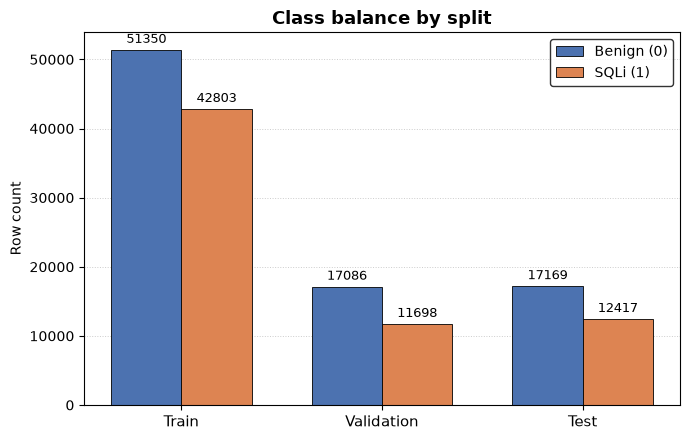

Saved figure: ./output/figures\query_length.png


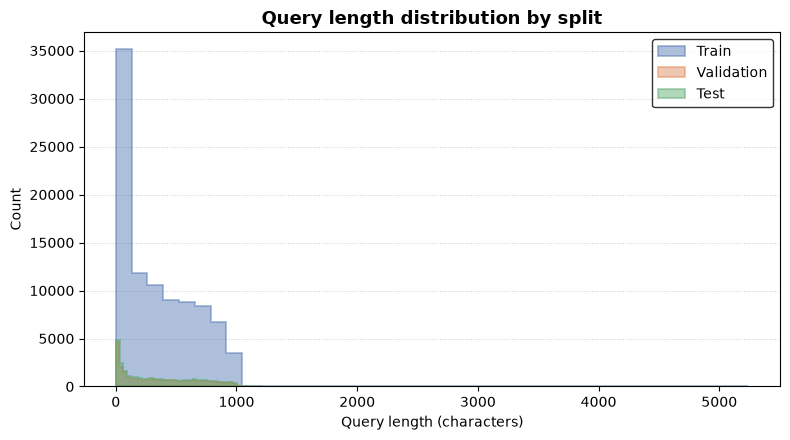


-- Benign examples --
  the film 'nightbreed' is one of the best horror films i have ever seen. overall, i'm not a big fan o
  the story for hare rama hare krishna actually came to dev anand's mind when he saw hippies and their
  atiy
  c/ doctor ferran, 193
  delete from push

-- SQLi examples --
  1" where 6347 = 6347 union all select null,null,null,null,null,null,null,null#
  jk dv1z0r39am1wjiiumia9xrxdowuo87f 110dcc d0ejn372pgx gdvynlkx2bpdzo3fgh5n2iyj8j8iqamt3mgn 7a8a2kxq6
  1'|| ( select 'fdkl' where 4572 = 4572 union all select null,null,null,null,null,null,null,null,null
  okay. yes, this was a very-tight-budget movie with continuity errors (like single scenes obviously f
  1' ) and 2853 = cast ( ( chr ( 113 ) ||chr ( 113 ) ||chr ( 112 ) ||chr/*there's never a dull moment 

Row counts -> train: 94153, validation: 28784, test: 29586


In [6]:
def plot_class_balance(splits, filename="class_balance"):
    """Grouped bar chart: benign vs SQLi count for each split."""
    names = [n for n, d in splits if d is not None]
    benign = [int((d["label"] == 0).sum()) for n, d in splits if d is not None]
    sqli = [int((d["label"] == 1).sum()) for n, d in splits if d is not None]

    x = np.arange(len(names))
    width = 0.35
    fig, ax = plt.subplots(figsize=(7, 4.5))
    b1 = ax.bar(x - width / 2, benign, width, color="#4C72B0", edgecolor="black",
                linewidth=0.6, label="Benign (0)")
    b2 = ax.bar(x + width / 2, sqli, width, color="#DD8452", edgecolor="black",
                linewidth=0.6, label="SQLi (1)")
    ax.bar_label(b1, padding=3, fontsize=9)
    ax.bar_label(b2, padding=3, fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels([n.capitalize() for n in names], fontsize=11)
    ax.set_ylabel("Row count")
    ax.set_title("Class balance by split", fontsize=13, fontweight="bold")
    ax.legend(frameon=True, edgecolor="black", fontsize=10)
    ax.grid(axis="y", linestyle=":", color="0.8", linewidth=0.7)
    ax.set_axisbelow(True)
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()
    plt.close(fig)


def plot_query_length(splits, filename="query_length"):
    """Overlaid histograms of query character length, one color per split."""
    colors = ["#4C72B0", "#DD8452", "#55A868"]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for (name, d), color in zip(splits, colors):
        if d is None:
            continue
        lengths = d["text"].str.len()
        ax.hist(lengths, bins=40, histtype="stepfilled", alpha=0.45,
                color=color, edgecolor=color, linewidth=1.4, label=name.capitalize())
    ax.set_xlabel("Query length (characters)")
    ax.set_ylabel("Count")
    ax.set_title("Query length distribution by split", fontsize=13, fontweight="bold")
    ax.legend(frameon=True, edgecolor="black", fontsize=10)
    ax.grid(axis="y", linestyle=":", color="0.8", linewidth=0.7)
    ax.set_axisbelow(True)
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()
    plt.close(fig)


def show_sample_queries(df, n=5):
    """Print a few benign and SQLi examples so the labels look sane."""
    for label, name in [(0, "Benign"), (1, "SQLi")]:
        print(f"\n-- {name} examples --")
        sample = df[df["label"] == label]["text"].head(n)
        for s in sample:
            print(f"  {s[:100]}")


_splits = [("train", train_df), ("validation", val_df), ("test", test_df)]

plot_class_balance(_splits)
plot_query_length(_splits)
show_sample_queries(train_df)

print("\nRow counts -> " + ", ".join(
    f"{n}: {len(d)}" for n, d in _splits if d is not None
))

## 4. Feature extraction techniques
The notebook evaluates character TF-IDF, word TF-IDF + PCA, Word2Vec, Keras
Tokenizer, BERT Tokenizer, and RoBERTa Tokenizer. Each function fits only on
training data and transforms train, validation, and test consistently.

Representations are returned as `(Xtr, Xval, Xte, kind[, vocab_size])`, where
`kind` is `"dense"`, `"sparse"`, or `"sequence"`.


In [7]:
def feat_tfidf_char(X_train_text, X_val_text, X_test_text):
    vec = TfidfVectorizer(analyzer="char")
    Xtr = vec.fit_transform(X_train_text)
    Xval = vec.transform(X_val_text)
    Xte = vec.transform(X_test_text)
    return Xtr, Xval, Xte, "sparse"


def feat_tfidf_word_pca(X_train_text, X_val_text, X_test_text, n_components, max_features):
    vec = TfidfVectorizer(analyzer="word", max_features=max_features)
    Xtr = vec.fit_transform(X_train_text).toarray()
    Xval = vec.transform(X_val_text).toarray()
    Xte = vec.transform(X_test_text).toarray()
    n_components = min(n_components, Xtr.shape[0], Xtr.shape[1])
    pca = PCA(n_components=n_components, random_state=SEED)
    Xtr_p = pca.fit_transform(Xtr)
    Xval_p = pca.transform(Xval)
    Xte_p = pca.transform(Xte)
    return Xtr_p, Xval_p, Xte_p, "dense"


def _tokenize_simple(s):
    return re.findall(r"[a-zA-Z_]+|\d+|[^\sa-zA-Z0-9]", s)


def feat_word2vec(X_train_text, X_val_text, X_test_text, params):
    tok_train = [_tokenize_simple(s) for s in X_train_text]
    tok_val = [_tokenize_simple(s) for s in X_val_text]
    tok_test = [_tokenize_simple(s) for s in X_test_text]
    w2v = Word2Vec(sentences=tok_train, **params)

    def sentence_vec(tokens):
        vecs = [w2v.wv[t] for t in tokens if t in w2v.wv]
        if not vecs:
            return np.zeros(params["vector_size"])
        return np.mean(vecs, axis=0)

    Xtr = np.vstack([sentence_vec(t) for t in tok_train])
    Xval = np.vstack([sentence_vec(t) for t in tok_val])
    Xte = np.vstack([sentence_vec(t) for t in tok_test])
    return Xtr, Xval, Xte, "dense"


def feat_keras_tokenizer(X_train_text, X_val_text, X_test_text, vocab_size, max_len):
    tok = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
    tok.fit_on_texts(X_train_text)

    def to_padded(texts):
        seqs = tok.texts_to_sequences(texts)
        return pad_sequences(seqs, maxlen=max_len, padding="post", truncating="post")

    Xtr = to_padded(X_train_text)
    Xval = to_padded(X_val_text)
    Xte = to_padded(X_test_text)
    return Xtr, Xval, Xte, "sequence", tok.num_words or vocab_size


def _hf_call_with_retry(fn, *args, max_retries=4, base_delay=2, **kwargs):
    """Hugging Face Hub calls can hit transient network errors
    (RemoteProtocolError: 'Server disconnected...', read timeouts, etc.)
    even when the model/tokenizer is already cached locally -- this
    transformers version still probes the Hub for chat-template files on
    every from_pretrained()/pipeline() call. Retry with backoff instead of
    losing an entire multi-hour pipeline run to one dropped connection."""
    last_err = None
    for attempt in range(1, max_retries + 1):
        try:
            return fn(*args, **kwargs)
        except Exception as e:
            last_err = e
            print(f"    [hf retry {attempt}/{max_retries}] {type(e).__name__}: {e}")
            time.sleep(base_delay * attempt)
    raise last_err


def feat_hf_tokenizer(X_train_text, X_val_text, X_test_text, model_name, max_len):
    from transformers import AutoTokenizer

    tok = _hf_call_with_retry(AutoTokenizer.from_pretrained, model_name)

    def encode(texts):
        enc = tok(
            list(texts),
            padding="max_length",
            truncation=True,
            max_length=max_len,
            return_tensors="np",
        )
        return enc["input_ids"]

    Xtr = encode(X_train_text)
    Xval = encode(X_val_text)
    Xte = encode(X_test_text)
    return Xtr, Xval, Xte, "sequence", tok.vocab_size


## 5. Classical models — every model is tuned with GridSearchCV under
StratifiedKFold instead of fixed, trial-and-error hyperparameters.
(Trained/tuned on Train only; Validation is reserved for the deep models
below; final numbers reported on Test.)

In [8]:
CV = StratifiedKFold(n_splits=CONFIG["N_SPLITS"], shuffle=True, random_state=SEED)

CLASSICAL_MODELS = {
    "Decision Tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"max_depth": [10, 20, None], "min_samples_split": [2, 5]},
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=SEED, n_jobs=-1),
        {"n_estimators": [100, 300], "max_depth": [16, None], "bootstrap": [False, True]},
    ),
    "LDA": (
        LinearDiscriminantAnalysis(),
        {"solver": ["svd", "lsqr"]},
    ),
    "MLP": (
        MLPClassifier(random_state=SEED, max_iter=300),
        {"hidden_layer_sizes": [(128, 64), (256, 128)], "alpha": [1e-4, 1e-3]},
    ),
    # --- New models added for a fuller comparison ---
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, random_state=SEED),
        {"C": [0.1, 1.0, 10.0]},
    ),
    "Linear SVM": (
        CalibratedClassifierCV(LinearSVC(random_state=SEED, max_iter=5000), cv=3),
        {"estimator__C": [0.1, 1.0, 10.0]},
    ),
    "KNN": (
        # GridSearchCV already parallelizes model search, so keep KNN itself
        # single-threaded to avoid nested parallelism and unnecessary memory use.
        KNeighborsClassifier(n_jobs=1),
        {"n_neighbors": [5, 11, 21]},
    ),
    "Gaussian Naive Bayes": (
        GaussianNB(),
        {"var_smoothing": [1e-9, 1e-7]},
    ),
    "AdaBoost": (
        AdaBoostClassifier(random_state=SEED),
        {"n_estimators": [100, 200], "learning_rate": [0.5, 1.0]},
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=SEED),
        {"n_estimators": [100, 200], "max_depth": [3, 5]},
    ),
}
if HAS_XGB:
    CLASSICAL_MODELS["XGBoost"] = (
        XGBClassifier(
            random_state=SEED, eval_metric="logloss", n_jobs=-1, use_label_encoder=False
        ),
        {"n_estimators": [200, 400], "max_depth": [4, 8], "learning_rate": [0.05, 0.1]},
    )

if CONFIG["FAST_MODE"]:
    # Shrink every grid to a single combo so FAST_MODE really is fast —
    # tuning is skipped, only used to sanity-check the pipeline runs.
    CLASSICAL_MODELS = {
        name: (model, {k: [v[0]] for k, v in grid.items()})
        for name, (model, grid) in CLASSICAL_MODELS.items()
    }


def to_dense(X):
    return X.toarray() if hasattr(X, "toarray") else np.asarray(X)


def run_classical_model(name, model, param_grid, Xtr, ytr, Xte, yte):
    t0 = time.time()
    Xtr_d, Xte_d = to_dense(Xtr), to_dense(Xte)
    search = GridSearchCV(
        model, param_grid, cv=CV, scoring="f1", n_jobs=-1, refit=True
    )
    search.fit(Xtr_d, ytr)
    best = search.best_estimator_
    preds = best.predict(Xte_d)

    metrics = dict(
        accuracy=accuracy_score(yte, preds) * 100,
        precision=precision_score(yte, preds, zero_division=0) * 100,
        recall=recall_score(yte, preds, zero_division=0) * 100,
        f1=f1_score(yte, preds, zero_division=0) * 100,
        best_params=json.dumps(search.best_params_),
        cv_f1_mean=search.best_score_ * 100,
        fit_seconds=elapsed_since(t0),
    )
    print(f"    {name}: {metrics['fit_seconds']}s, F1={metrics['f1']:.1f}%")
    cm = confusion_matrix(yte, preds)
    return metrics, cm, best

## 6. Deep models (CNN / BiLSTM on sequence inputs — unchanged architecture
from the paper, but now validated against the dataset's real Validation
split, with early stopping added as a training-quality improvement)

In [9]:
def build_cnn(vocab_size, max_len, embed_dim=128, num_filters=128, kernel_sizes=(3, 4, 5)):
    model = Sequential()
    model.add(Embedding(input_dim=vocab_size + 1, output_dim=embed_dim, input_length=max_len))
    model.add(Conv1D(num_filters, kernel_sizes[0], activation="relu"))
    model.add(GlobalMaxPooling1D())
    model.add(Dense(64, activation="relu"))
    model.add(Dropout(0.3))
    model.add(Dense(1, activation="sigmoid"))
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model


def build_bilstm(vocab_size, max_len, embed_dim=128, lstm_units=64):
    model = Sequential()
    model.add(Embedding(input_dim=vocab_size + 1, output_dim=embed_dim, input_length=max_len))
    model.add(Bidirectional(LSTM(lstm_units)))
    model.add(Dense(64, activation="relu"))
    model.add(Dropout(0.3))
    model.add(Dense(1, activation="sigmoid"))
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model


def run_deep_model(build_fn, vocab_size, Xtr, ytr, Xval, yval, Xte, yte, max_len,
                    epochs=10, batch_size=128):
    t0 = time.time()
    model = build_fn(vocab_size, max_len)
    es = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
    model.fit(
        Xtr,
        ytr,
        validation_data=(Xval, yval),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[es],
        verbose=0,
    )
    probs = model.predict(Xte, verbose=0).ravel()
    preds = (probs >= 0.5).astype(int)

    metrics = dict(
        accuracy=accuracy_score(yte, preds) * 100,
        precision=precision_score(yte, preds, zero_division=0) * 100,
        recall=recall_score(yte, preds, zero_division=0) * 100,
        f1=f1_score(yte, preds, zero_division=0) * 100,
        best_params=f"early_stopping(patience=2),epochs<={epochs}",
        cv_f1_mean=np.nan,
        fit_seconds=elapsed_since(t0),
    )
    print(f"    fit time: {metrics['fit_seconds']}s, F1={metrics['f1']:.1f}%")
    cm = confusion_matrix(yte, preds)
    return metrics, cm, probs

## 7. Orchestration — build every feature extraction technique once, then run
every classical model + (where sensible) the deep models against it.
Results are appended to a CSV so a Kaggle timeout doesn't lose progress, and
per-technique + total wall-clock time is tracked and printed.

In [10]:
RESULTS_COLUMNS = [
    "technique", "model", "accuracy", "precision", "recall", "f1",
    "best_params", "cv_f1_mean", "fit_seconds",
]



def append_result(row, csv_path=CONFIG["RESULTS_CSV"]):
    row = dict(row)  # don't mutate caller's dict
    # stringify anything that isn't a plain scalar (e.g. GridSearchCV best_params_
    # dicts), so commas/quotes inside them can't desync the column count on append
    if "best_params" in row and not isinstance(row["best_params"], (str, float, int, type(None))):
        row["best_params"] = str(row["best_params"])

    df_row = pd.DataFrame([row])
    # enforce a fixed column schema every time so appended rows always line up
    # with whatever header was written first, regardless of dict key order
    for col in RESULTS_COLUMNS:
        if col not in df_row.columns:
            df_row[col] = np.nan
    df_row = df_row[RESULTS_COLUMNS]

    write_header = not os.path.exists(csv_path)
    df_row.to_csv(csv_path, mode="a", header=write_header, index=False)


def already_done(technique, model_name, csv_path=CONFIG["RESULTS_CSV"]):
    if not os.path.exists(csv_path):
        return False
    done = _read_csv_robust(csv_path)
    return ((done["technique"] == technique) & (done["model"] == model_name)).any()


confusion_matrices = {}  # (technique, model_name) -> cm

FEATURE_TECHNIQUES = [
    "TF-IDF (char)",
    "TF-IDF+PCA(n=15)",
    "TF-IDF+PCA(n=512)",
    "Word2Vec",
    "Tokenizer",
]
if CONFIG["RUN_TRANSFORMER_TOKENIZERS"]:
    FEATURE_TECHNIQUES += [
        "BERT Tokenizer",
        "RoBERTa Tokenizer",
    ]

for technique in FEATURE_TECHNIQUES:
    technique_t0 = time.time()
    print(f"\n=== Building features: {technique} ===")
    vocab_size = None

    if technique == "TF-IDF (char)":
        Xtr, Xval, Xte, kind = feat_tfidf_char(X_train_text, X_val_text, X_test_text)
    elif technique == "TF-IDF+PCA(n=15)":
        Xtr, Xval, Xte, kind = feat_tfidf_word_pca(
            X_train_text, X_val_text, X_test_text, 15, CONFIG["TFIDF_WORD_MAX_FEATURES"]
        )
    elif technique == "TF-IDF+PCA(n=512)":
        Xtr, Xval, Xte, kind = feat_tfidf_word_pca(
            X_train_text, X_val_text, X_test_text, 512, CONFIG["TFIDF_WORD_MAX_FEATURES"]
        )
    elif technique == "Word2Vec":
        Xtr, Xval, Xte, kind = feat_word2vec(
            X_train_text, X_val_text, X_test_text, CONFIG["WORD2VEC_PARAMS"]
        )
    elif technique == "Tokenizer":
        Xtr, Xval, Xte, kind, vocab_size = feat_keras_tokenizer(
            X_train_text, X_val_text, X_test_text, CONFIG["TOKENIZER_VOCAB"], CONFIG["MAX_SEQ_LEN"]
        )
    elif technique == "BERT Tokenizer":
        Xtr, Xval, Xte, kind, vocab_size = feat_hf_tokenizer(
            X_train_text, X_val_text, X_test_text, "bert-base-uncased", CONFIG["MAX_SEQ_LEN"]
        )
    elif technique == "RoBERTa Tokenizer":
        Xtr, Xval, Xte, kind, vocab_size = feat_hf_tokenizer(
            X_train_text, X_val_text, X_test_text, "roberta-base", CONFIG["MAX_SEQ_LEN"]
        )
    else:
        continue

    print(f"  feature build time: {elapsed_since(technique_t0)}s")

    # --- classical models on every technique (dense/sparse-compatible) ---
    for model_name, (model, grid) in CLASSICAL_MODELS.items():
        if already_done(technique, model_name):
            print(f"  skip (cached): {model_name}")
            continue
        try:
            print(f"  fitting: {model_name}")
            metrics, cm, _ = run_classical_model(
                model_name, model, grid, Xtr, y_train, Xte, y_test
            )
            row = dict(technique=technique, model=model_name, **metrics)
            append_result(row)
            confusion_matrices[(technique, model_name)] = cm
        except Exception as e:
            print(f"  FAILED {model_name} on {technique}: {e}")

    # --- deep models only where the representation is a padded token sequence ---
    if kind == "sequence" and vocab_size:
        for dm_name, build_fn in [("CNN", build_cnn), ("BiLSTM", build_bilstm)]:
            if already_done(technique, dm_name):
                print(f"  skip (cached): {dm_name}")
                continue
            try:
                print(f"  fitting: {dm_name}")
                metrics, cm, _ = run_deep_model(
                    build_fn, vocab_size, Xtr, y_train, Xval, y_val, Xte, y_test,
                    CONFIG["MAX_SEQ_LEN"], epochs=CONFIG["DEEP_EPOCHS"],
                )
                row = dict(technique=technique, model=dm_name, **metrics)
                append_result(row)
                confusion_matrices[(technique, dm_name)] = cm
            except Exception as e:
                print(f"  FAILED {dm_name} on {technique}: {e}")
    TECHNIQUE_TIMES[technique] = elapsed_since(technique_t0)
    print(f"  >> '{technique}' total time: {TECHNIQUE_TIMES[technique]}s "
          f"({fmt_minutes(TECHNIQUE_TIMES[technique])})")


=== Building features: TF-IDF (char) ===
  feature build time: 17.3s
  skip (cached): Decision Tree
  skip (cached): Random Forest
  skip (cached): LDA
  skip (cached): MLP
  skip (cached): Logistic Regression
  skip (cached): Linear SVM
  skip (cached): KNN
  skip (cached): Gaussian Naive Bayes
  skip (cached): AdaBoost
  skip (cached): Gradient Boosting
  skip (cached): XGBoost
  >> 'TF-IDF (char)' total time: 17.4s (0.3 min)

=== Building features: TF-IDF+PCA(n=15) ===
  feature build time: 60.6s
  skip (cached): Decision Tree
  skip (cached): Random Forest
  skip (cached): LDA
  skip (cached): MLP
  skip (cached): Logistic Regression
  skip (cached): Linear SVM
  skip (cached): KNN
  skip (cached): Gaussian Naive Bayes
  skip (cached): AdaBoost
  skip (cached): Gradient Boosting
  skip (cached): XGBoost
  >> 'TF-IDF+PCA(n=15)' total time: 60.7s (1.0 min)

=== Building features: TF-IDF+PCA(n=512) ===
  feature build time: 201.3s
  skip (cached): Decision Tree
  skip (cached): Rando

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


  feature build time: 68.2s
  skip (cached): Decision Tree
  skip (cached): Random Forest
  skip (cached): LDA
  skip (cached): MLP
  skip (cached): Logistic Regression
  skip (cached): Linear SVM
  skip (cached): KNN
  skip (cached): Gaussian Naive Bayes
  skip (cached): AdaBoost
  skip (cached): Gradient Boosting
  skip (cached): XGBoost
  skip (cached): CNN
  skip (cached): BiLSTM
  >> 'BERT Tokenizer' total time: 68.2s (1.1 min)

=== Building features: RoBERTa Tokenizer ===
  feature build time: 53.9s
  skip (cached): Decision Tree
  skip (cached): Random Forest
  skip (cached): LDA
  skip (cached): MLP
  skip (cached): Logistic Regression
  skip (cached): Linear SVM
  skip (cached): KNN
  skip (cached): Gaussian Naive Bayes
  skip (cached): AdaBoost
  skip (cached): Gradient Boosting
  skip (cached): XGBoost
  skip (cached): CNN
  skip (cached): BiLSTM
  >> 'RoBERTa Tokenizer' total time: 53.9s (0.9 min)


## 8. Runtime summary — printed so you can see exactly where the time went

In [11]:
print("\n=== Runtime summary (seconds) by feature-extraction technique ===")
for tech, secs in TECHNIQUE_TIMES.items():
    print(f"  {tech:<22} {secs:>8.1f}s  ({fmt_minutes(secs)})")

TOTAL_SECONDS = elapsed_since(PIPELINE_START)
print(f"\nTOTAL PIPELINE RUNTIME: {TOTAL_SECONDS:.1f}s ({fmt_minutes(TOTAL_SECONDS)})")

if os.path.exists(CONFIG["RESULTS_CSV"]):
    _r = pd.read_csv(CONFIG["RESULTS_CSV"])
    if "fit_seconds" in _r.columns:
        print("\nSlowest 5 (technique, model) fits:")
        print(
            _r.sort_values("fit_seconds", ascending=False)[
                ["technique", "model", "fit_seconds", "f1"]
            ].head(5).to_string(index=False)
        )


=== Runtime summary (seconds) by feature-extraction technique ===
  TF-IDF (char)              17.4s  (0.3 min)
  TF-IDF+PCA(n=15)           60.7s  (1.0 min)
  TF-IDF+PCA(n=512)         201.4s  (3.4 min)
  Word2Vec                  158.8s  (2.6 min)
  Tokenizer                  21.8s  (0.4 min)
  BERT Tokenizer             68.2s  (1.1 min)
  RoBERTa Tokenizer          53.9s  (0.9 min)

TOTAL PIPELINE RUNTIME: 592.0s (9.9 min)

Slowest 5 (technique, model) fits:
        technique             model  fit_seconds        f1
TF-IDF+PCA(n=512) Gradient Boosting      18361.0 96.985896
 TF-IDF+PCA(n=15)               MLP       9205.7 96.497064
TF-IDF+PCA(n=512)     Random Forest       8106.4 96.344550
TF-IDF+PCA(n=512)          AdaBoost       5667.1 92.870794
    TF-IDF (char)               MLP       4979.9 99.065195


## 9. Final figures
Comparison charts (metric-by-model-technique bars and the leaderboard) use color for readability now that there are up to 11 series on one axis. Confusion matrices stay strictly grayscale.

       technique                model   accuracy  precision     recall  \
0  TF-IDF (char)        Decision Tree  98.698709  98.910569  97.978578   
1  TF-IDF (char)        Random Forest  99.300345  99.481277  98.848353   
2  TF-IDF (char)                  LDA  88.707497  93.760849  78.303938   
3  TF-IDF (char)                  MLP  99.215845  99.129102  99.001369   
4  TF-IDF (char)  Logistic Regression  91.117420  93.736038  84.480954   

          f1                                        best_params  cv_f1_mean  \
0  98.442368          {"max_depth": 20, "min_samples_split": 2}   98.240505   
1  99.163805  {"bootstrap": false, "max_depth": null, "n_est...   99.142465   
2  85.338131                                  {"solver": "svd"}   86.957549   
3  99.065195  {"alpha": 0.0001, "hidden_layer_sizes": [256, ...   99.008443   
4  88.868180                                        {"C": 10.0}   89.731860   

   fit_seconds  
0        103.9  
1        885.5  
2         24.5  
3       4979

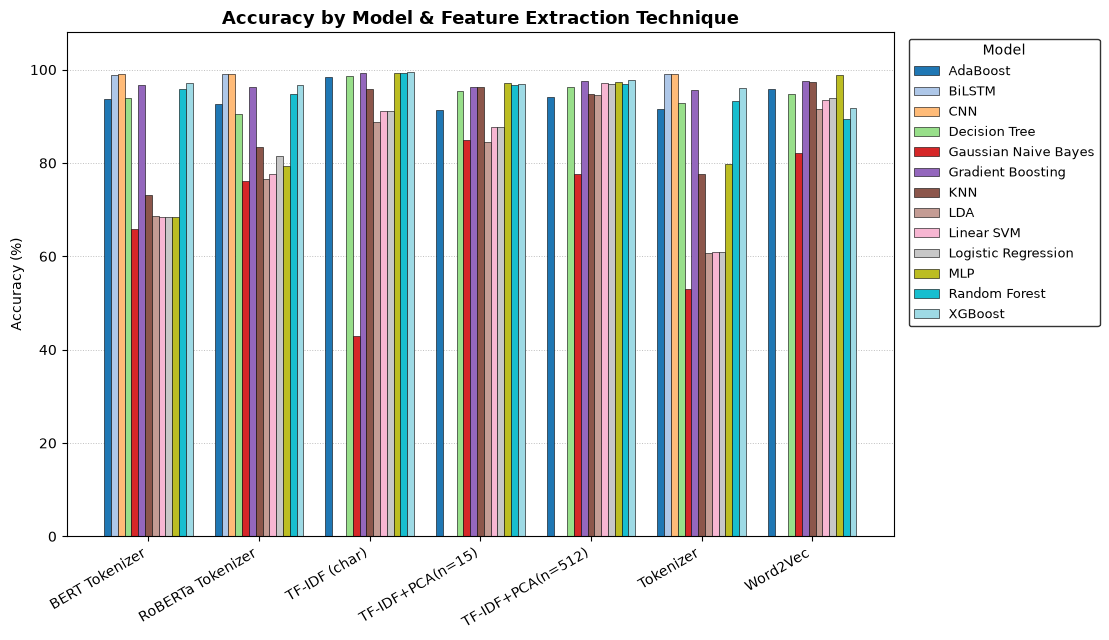

Saved figure: ./output/figures\precision_by_model_technique.png


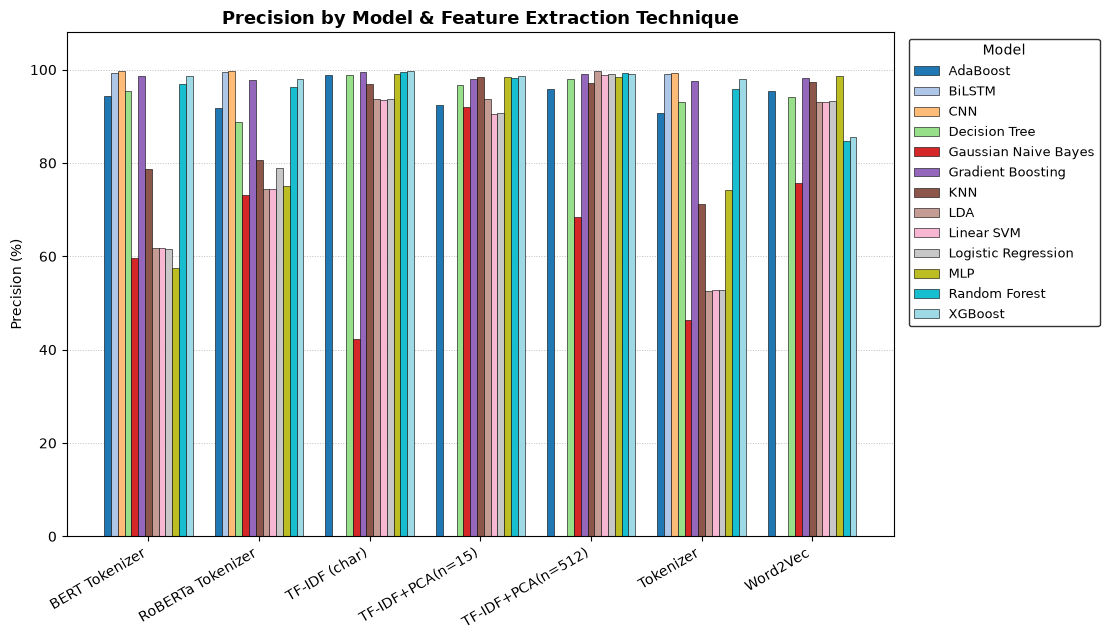

Saved figure: ./output/figures\recall_by_model_technique.png


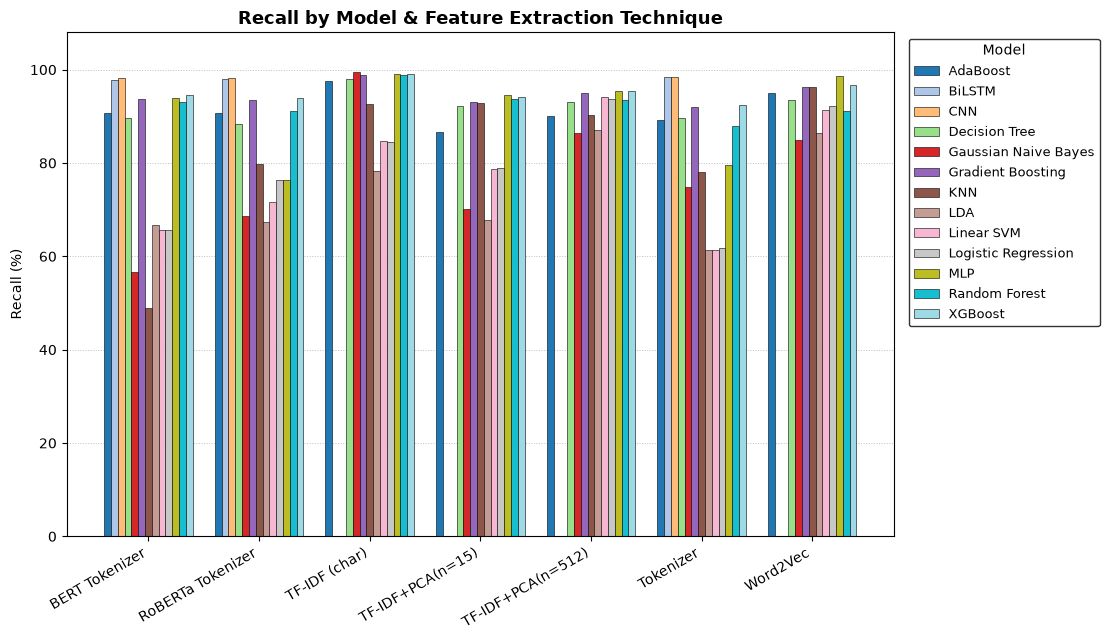

Saved figure: ./output/figures\f1_by_model_technique.png


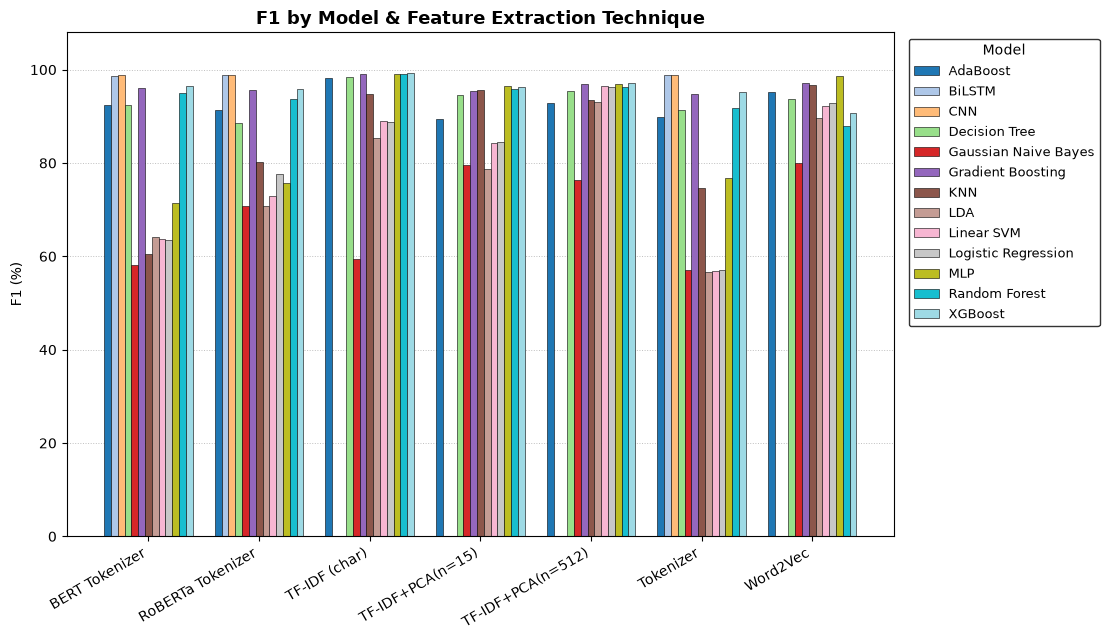

Saved figure: ./output/figures\leaderboard.png


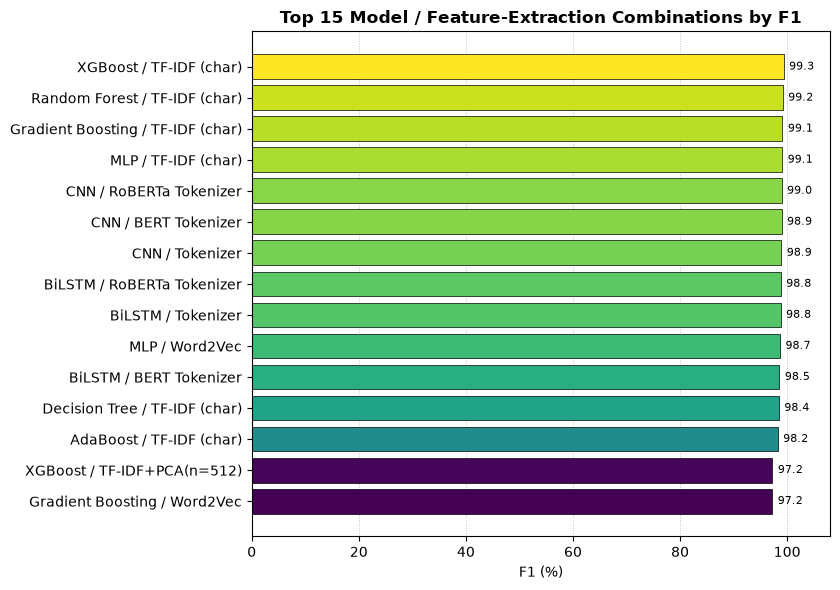


All done. Results table saved to: ./output\results_extended.csv
Figures saved under: ./output/figures/
Grand total runtime: 600.4s (10.0 min)


In [12]:
results_df = pd.read_csv(CONFIG["RESULTS_CSV"])
print(results_df.head())

# From here on, only the confusion matrices stay strictly grayscale (they're
# meant to be printable/copy-safe). The comparison charts below use color --
# with 9-11 series on one axis, grayscale + hatch alone got hard to read.
CMAP_MODELS = plt.get_cmap("tab20")


def plot_grouped_bar(df, metric, title, filename):
    pivot = df.pivot(index="technique", columns="model", values=metric)
    techniques = pivot.index.tolist()
    models = pivot.columns.tolist()
    n_models = len(models)
    colors = CMAP_MODELS(np.linspace(0, 1, n_models))

    x = np.arange(len(techniques))
    width = 0.8 / max(n_models, 1)

    fig, ax = plt.subplots(figsize=(max(11, len(techniques) * 1.6), 6.5))
    for i, model in enumerate(models):
        vals = pivot[model].values
        ax.bar(
            x + i * width - 0.4 + width / 2,
            vals,
            width=width,
            color=colors[i],
            edgecolor="black",
            linewidth=0.4,
            label=model,
        )
    ax.set_xticks(x)
    ax.set_xticklabels(techniques, rotation=30, ha="right")
    ax.set_ylabel(f"{metric.capitalize()} (%)")
    ax.set_ylim(0, 108)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.legend(
        loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=9,
        frameon=True, edgecolor="black", title="Model",
    )
    ax.grid(axis="y", linestyle=":", color="0.75", linewidth=0.7)
    ax.set_axisbelow(True)
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()
    plt.close(fig)


for metric in ["accuracy", "precision", "recall", "f1"]:
    plot_grouped_bar(
        results_df, metric, f"{metric.capitalize()} by Model & Feature Extraction Technique",
        f"{metric}_by_model_technique",
    )


def plot_confusion_matrix_bw(cm, title, filename, labels=("Benign", "SQLi")):
    """Kept strictly grayscale on purpose (see note above)."""
    total = cm.sum()
    fig, ax = plt.subplots(figsize=(4.2, 4.2))
    im = ax.imshow(cm, cmap="Greys")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(labels, fontsize=10)
    ax.set_yticklabels(labels, fontsize=10)
    ax.set_xlabel("Predicted", fontsize=10)
    ax.set_ylabel("Actual", fontsize=10)
    ax.set_title(title, fontsize=10)
    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            color = "white" if cm[i, j] > thresh else "black"
            pct = cm[i, j] / total * 100 if total else 0
            ax.text(
                j, i, f"{cm[i, j]:d}\n({pct:.1f}%)",
                ha="center", va="center", color=color, fontsize=10,
            )
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Count")
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()
    plt.close(fig)


# Confusion matrices for the best F1-scoring combo per model (compact set,
# rather than every technique x model pair, to keep output manageable).
best_per_model = results_df.sort_values("f1", ascending=False).drop_duplicates("model")
for _, row in best_per_model.iterrows():
    key = (row["technique"], row["model"])
    if key in confusion_matrices:
        plot_confusion_matrix_bw(
            confusion_matrices[key],
            f"{row['model']} — {row['technique']} (best F1={row['f1']:.1f}%)",
            f"cm_{row['model']}_{row['technique']}".replace(" ", "_").replace("(", "").replace(")", ""),
        )


def plot_leaderboard(df, metric="f1", top_n=15, filename="leaderboard"):
    ranked = df.sort_values(metric, ascending=False).head(top_n).iloc[::-1]
    labels = ranked["model"] + " / " + ranked["technique"]
    vals = ranked[metric].values
    norm = (vals - vals.min()) / (vals.max() - vals.min() + 1e-9)
    colors = plt.get_cmap("viridis")(norm)

    fig, ax = plt.subplots(figsize=(8.5, max(4.5, top_n * 0.4)))
    bars = ax.barh(labels, vals, color=colors, edgecolor="black", linewidth=0.5)
    ax.bar_label(bars, fmt="%.1f", padding=4, fontsize=8)
    ax.set_xlabel(f"{metric.capitalize()} (%)")
    ax.set_xlim(0, 108)
    ax.set_title(f"Top {top_n} Model / Feature-Extraction Combinations by {metric.capitalize()}",
                 fontsize=12, fontweight="bold")
    ax.grid(axis="x", linestyle=":", color="0.75", linewidth=0.7)
    ax.set_axisbelow(True)
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()
    plt.close(fig)


plot_leaderboard(results_df, metric="f1")

print("\nAll done. Results table saved to:", CONFIG["RESULTS_CSV"])
print("Figures saved under: ./output/figures/")
print(f"Grand total runtime: {elapsed_since(PIPELINE_START):.1f}s ({fmt_minutes(elapsed_since(PIPELINE_START))})")

## 10. Explainability (XAI): LIME (local) + SHAP (global)
Targets the best classical model on **TF-IDF (char)** specifically -- that technique keeps the feature space small (one feature per distinct character), so it's cheap to refit and every feature has a human-readable meaning, unlike PCA components or Word2Vec dimensions.

- **LIME** explains a handful of individual predictions (a caught SQLi query, a missed one if any exist, and a correctly-passed benign query) by highlighting which characters push the prediction toward SQLi vs benign.
- **SHAP** (`KernelExplainer`) gives a global summary: which characters matter most across a sample of the test set, and in which direction.

Requires `lime` and `shap` (`pip install lime shap`).

XAI target: XGBoost on TF-IDF (char) (F1=99.3%)

XAI figures directory:
./output\figures\xai

Available test cases:
true_negative    index=0
true_positive    index=6
false_negative   index=83
false_positive   index=839

LIME: TRUE NEGATIVE
Query: a pretentious but - to varying degrees - watchable collection of mostly pointless "stories".<br /><br />but let's start 
Predicted: Benign
P(Benign): 0.9983
P(SQLi): 0.0017

Important features:
np.str_('i') -0.0245 -> Benign
np.str_('a') -0.0235 -> Benign
np.str_('o') -0.0211 -> Benign
np.str_('h') -0.0173 -> Benign
np.str_('t') -0.0171 -> Benign
np.str_('f') -0.0166 -> Benign
np.str_('r') -0.0150 -> Benign
np.str_('g') -0.0136 -> Benign
np.str_('"') +0.0134 -> SQLi
np.str_('-') +0.0082 -> SQLi
np.str_("'") +0.0062 -> SQLi
np.str_(' ') +0.0058 -> SQLi


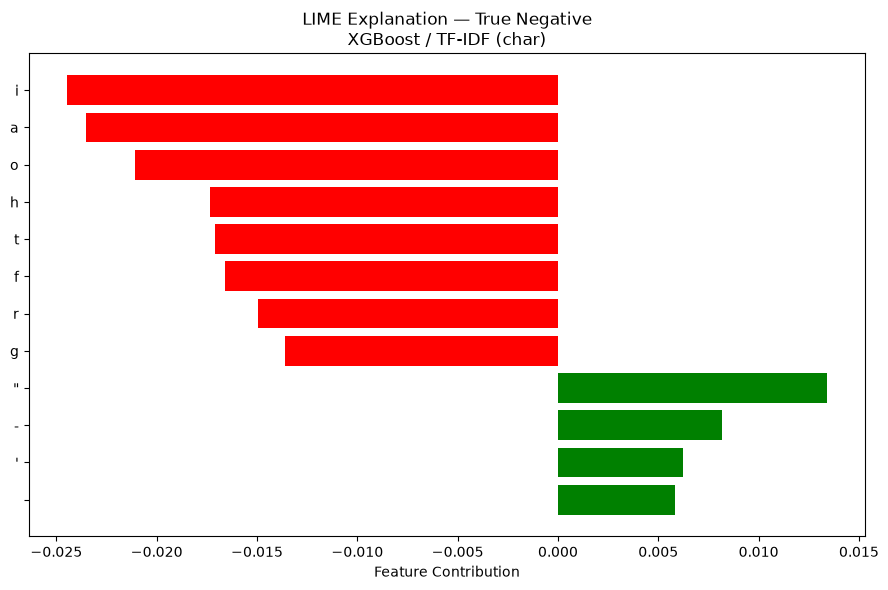

Saved: ./output\figures\xai\lime_true_negative.png

LIME: TRUE POSITIVE
Query: xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx
Predicted: SQLi
P(Benign): 0.0000
P(SQLi): 1.0000

Important features:
np.str_('x') +0.0589 -> SQLi
np.str_('=') +0.0583 -> SQLi
np.str_(')') +0.0462 -> SQLi
np.str_('|') +0.0431 -> SQLi
np.str_("'") +0.0250 -> SQLi
np.str_('(') +0.0114 -> SQLi
np.str_('e') -0.0113 -> Benign
np.str_('q') +0.0109 -> SQLi
np.str_('i') +0.0086 -> SQLi
np.str_('o') +0.0083 -> SQLi
np.str_('-') +0.0070 -> SQLi
np.str_('h') -0.0068 -> Benign


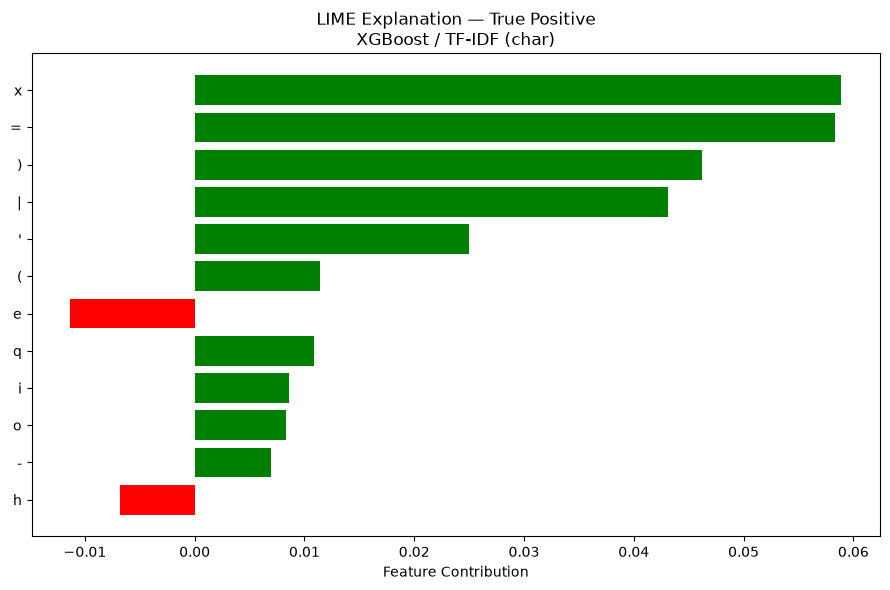

Saved: ./output\figures\xai\lime_true_positive.png

LIME: FALSE NEGATIVE
Query: most of the films i really like are art-house fare and seldom appear on the box-office top-ten lists. that said, i found
Predicted: Benign
P(Benign): 0.9617
P(SQLi): 0.0383

Important features:
np.str_('t') -0.0489 -> Benign
np.str_('a') -0.0384 -> Benign
np.str_('-') +0.0373 -> SQLi
np.str_('o') -0.0365 -> Benign
np.str_('w') -0.0352 -> Benign
np.str_('"') +0.0337 -> SQLi
np.str_("'") +0.0331 -> SQLi
np.str_('5') +0.0315 -> SQLi
np.str_('h') -0.0289 -> Benign
np.str_('y') -0.0269 -> Benign
np.str_('i') -0.0246 -> Benign
np.str_(' ') +0.0243 -> SQLi


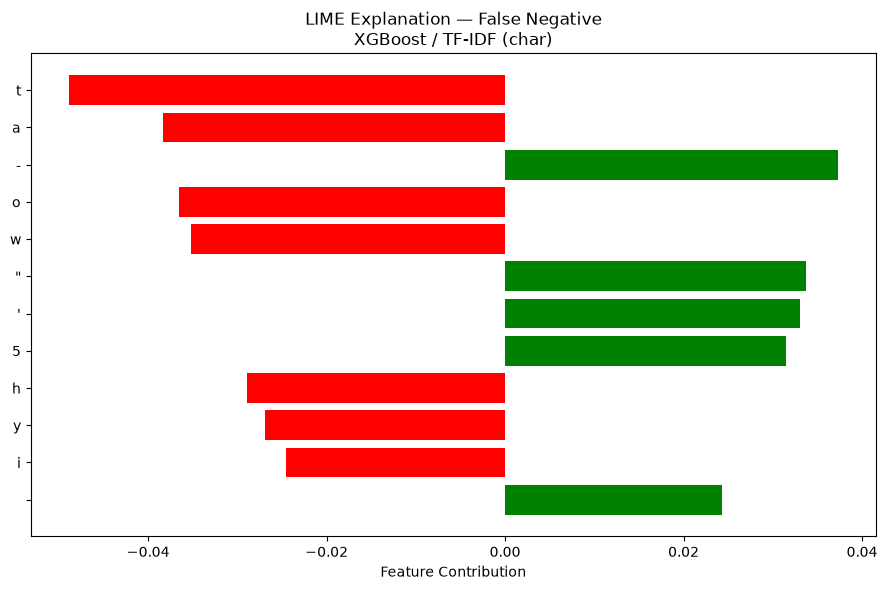

Saved: ./output\figures\xai\lime_false_negative.png

LIME: FALSE POSITIVE
Query: i was also disappointed with this movie. for starters, the things that happen to him don't seem too terrible to me (sorr
Predicted: SQLi
P(Benign): 0.4566
P(SQLi): 0.5434

Important features:
np.str_('_') +0.4097 -> SQLi
np.str_('*') +0.2437 -> SQLi
np.str_(' ') +0.1663 -> SQLi
np.str_('"') +0.1366 -> SQLi
np.str_('t') -0.1180 -> Benign
np.str_('o') -0.1060 -> Benign
np.str_(')') +0.0977 -> SQLi
np.str_('(') -0.0897 -> Benign
np.str_('m') -0.0775 -> Benign
np.str_('y') -0.0762 -> Benign
np.str_('h') -0.0738 -> Benign
np.str_('a') -0.0642 -> Benign


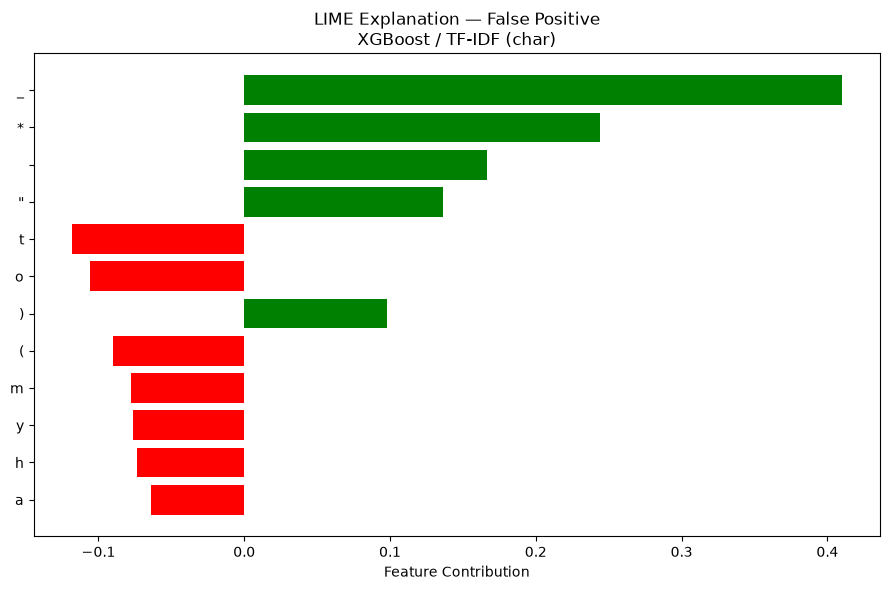

Saved: ./output\figures\xai\lime_false_positive.png

Building SHAP KernelExplainer...
Calculating SHAP values...


100%|██████████| 50/50 [00:03<00:00, 14.29it/s]


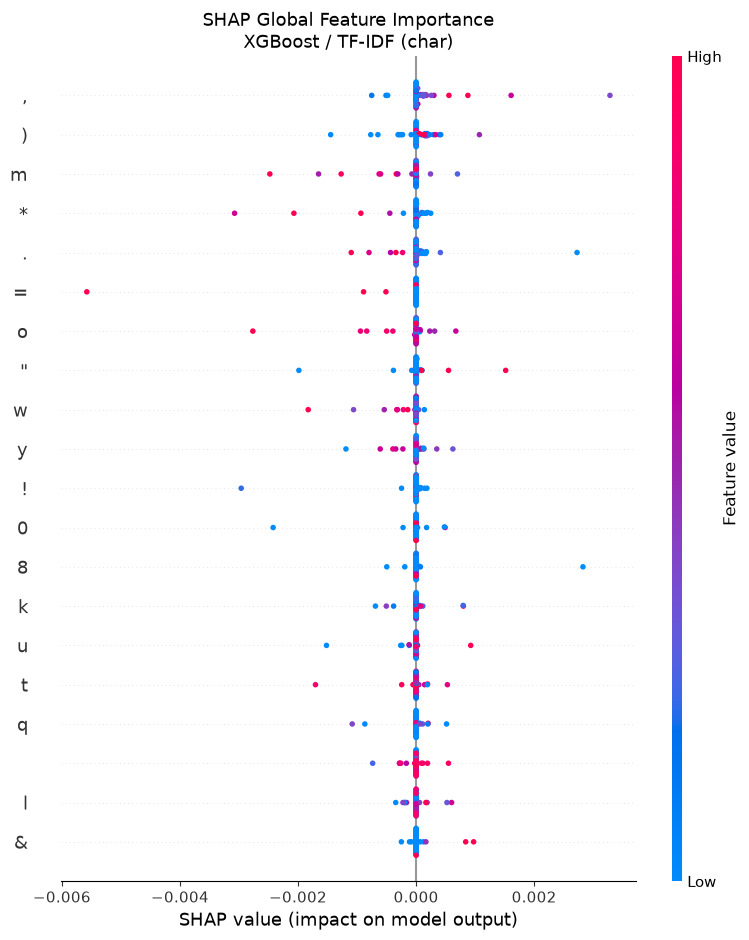


Saved SHAP summary: ./output\figures\xai\shap_summary.png

XAI ANALYSIS COMPLETED

All figures saved under:
./output\figures\xai

Generated images:
  lime_true_negative.png
  lime_true_positive.png
  lime_false_negative.png
  lime_false_positive.png
  shap_summary.png


{'model_name': 'XGBoost',
 'model': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=None, device=None, early_stopping_rounds=None,
               enable_categorical=False, eval_metric='logloss',
               feature_types=None, feature_weights=None, gamma=None,
               grow_policy=None, importance_type=None,
               interaction_constraints=None, learning_rate=None, max_bin=None,
               max_cat_threshold=None, max_cat_to_onehot=None,
               max_delta_step=None, max_depth=None, max_leaves=None,
               min_child_weight=None, missing=nan, monotone_constraints=None,
               multi_strategy=None, n_estimators=None, n_jobs=-1,
               num_parallel_tree=None, ...),
 'vectorizer': TfidfVectorizer(analyzer='char'),
 'lime_explanations': {'true_negative': <lime.explanation.Explanation at 0x14e90b06110>,
  'true_positive': <lime.explanation

In [13]:
from sklearn.base import clone

try:
    from lime.lime_text import LimeTextExplainer
    import shap
except ImportError as e:
    raise ImportError(
        "This cell needs the `lime` and `shap` packages: pip install lime shap"
    ) from e


def run_xai_analysis(results_df):
    """
    Run XAI analysis for the best classical model using TF-IDF (char).

    Generates:
        - LIME explanations as PNG images
        - SHAP global summary plot as PNG image

    No SHAP force plots are generated.
    """

    # ========================================================================
    # 1. Select best classical model using TF-IDF (char)
    # ========================================================================

    classical_names = set(CLASSICAL_MODELS.keys())

    candidates = results_df[
        (results_df["model"].isin(classical_names))
        & (results_df["technique"] == "TF-IDF (char)")
    ]

    if candidates.empty:
        raise ValueError(
            "No classical-model results found for 'TF-IDF (char)' "
            "in results_df."
        )

    best_row = candidates.sort_values(
        "f1",
        ascending=False
    ).iloc[0]

    best_model_name = best_row["model"]

    print(
        f"XAI target: {best_model_name} on TF-IDF (char) "
        f"(F1={best_row['f1']:.1f}%)"
    )

    # ========================================================================
    # 2. Refit selected model
    # ========================================================================

    xai_vectorizer = TfidfVectorizer(
        analyzer="char"
    )

    Xtr_xai = xai_vectorizer.fit_transform(
        X_train_text
    )

    xai_model_proto, _ = CLASSICAL_MODELS[
        best_model_name
    ]

    xai_model = clone(
        xai_model_proto
    )

    xai_model.fit(
        Xtr_xai,
        y_train
    )

    feature_names = np.array(
        xai_vectorizer.get_feature_names_out()
    )

    # ========================================================================
    # 3. Prediction wrapper
    # ========================================================================

    def xai_predict_proba(texts):
        """
        Convert raw text into class probabilities.
        """

        X = xai_vectorizer.transform(texts)

        if hasattr(
            xai_model,
            "predict_proba"
        ):
            return xai_model.predict_proba(X)

        # Fallback for classifiers without predict_proba
        scores = xai_model.decision_function(X)

        probs_pos = 1 / (
            1 + np.exp(-scores)
        )

        return np.column_stack([
            1 - probs_pos,
            probs_pos
        ])

    # ========================================================================
    # 4. Output directory
    # ========================================================================

    xai_dir = os.path.join(
        CONFIG["OUTPUT_DIR"],
        "figures",
        "xai"
    )

    os.makedirs(
        xai_dir,
        exist_ok=True
    )

    print(
        f"\nXAI figures directory:\n{xai_dir}"
    )

    # ========================================================================
    # 5. Calculate test predictions
    # ========================================================================

    test_probabilities = xai_predict_proba(
        X_test_text
    )

    test_preds = (
        test_probabilities[:, 1] >= 0.5
    ).astype(int)

    # ========================================================================
    # 6. Find TP, FN, TN and FP examples
    # ========================================================================

    wanted = {

        "true_positive":
            lambda t, p:
            t == 1 and p == 1,

        "false_negative":
            lambda t, p:
            t == 1 and p == 0,

        "true_negative":
            lambda t, p:
            t == 0 and p == 0,

        "false_positive":
            lambda t, p:
            t == 0 and p == 1,
    }

    sample_idx = {}

    for i, (true_label, pred_label) in enumerate(
        zip(y_test, test_preds)
    ):

        for case, condition in wanted.items():

            if (
                case not in sample_idx
                and condition(
                    true_label,
                    pred_label
                )
            ):
                sample_idx[case] = i

    print("\nAvailable test cases:")

    for case, idx in sample_idx.items():

        print(
            f"{case:16s} "
            f"index={idx}"
        )

    # ========================================================================
    # 7. LIME Explainer
    # ========================================================================

    lime_explainer = LimeTextExplainer(
        class_names=[
            "Benign",
            "SQLi"
        ],
        char_level=True
    )

    def save_lime_explanation(
        query,
        case_name,
        num_features=12
    ):
        """
        Generate one LIME explanation
        and save it as PNG.
        """

        probabilities = xai_predict_proba(
            [query]
        )[0]

        pred_class = int(
            probabilities[1] >= 0.5
        )

        pred_label = (
            "SQLi"
            if pred_class == 1
            else "Benign"
        )

        print(
            "\n" + "=" * 60
        )

        print(
            f"LIME: "
            f"{case_name.replace('_', ' ').upper()}"
        )

        print(
            "=" * 60
        )

        print(
            f"Query: {query[:120]}"
        )

        print(
            f"Predicted: {pred_label}"
        )

        print(
            f"P(Benign): "
            f"{probabilities[0]:.4f}"
        )

        print(
            f"P(SQLi): "
            f"{probabilities[1]:.4f}"
        )

        # Generate explanation
        exp = lime_explainer.explain_instance(
            query,
            xai_predict_proba,
            num_features=num_features
        )

        print(
            "\nImportant features:"
        )

        for token, weight in exp.as_list():

            direction = (
                "-> SQLi"
                if weight > 0
                else "-> Benign"
            )

            print(
                f"{token!r:12s} "
                f"{weight:+.4f} "
                f"{direction}"
            )

        # ================================================================
        # Save LIME as image
        # ================================================================

        fig = exp.as_pyplot_figure()

        fig.set_size_inches(
            9,
            6
        )

        plt.title(
            f"LIME Explanation — "
            f"{case_name.replace('_', ' ').title()}\n"
            f"{best_model_name} / TF-IDF (char)",
            fontsize=12
        )

        plt.xlabel(
            "Feature Contribution"
        )

        plt.tight_layout()

        lime_path = os.path.join(
            xai_dir,
            f"lime_{case_name}.png"
        )

        fig.savefig(
            lime_path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

        plt.close(fig)

        print(
            f"Saved: {lime_path}"
        )

        return exp

    # ========================================================================
    # 8. Generate LIME images
    # ========================================================================

    lime_explanations = {}

    for case, idx in sample_idx.items():

        query = str(
            X_test_text[idx]
        )

        lime_explanations[case] = (
            save_lime_explanation(
                query=query,
                case_name=case,
                num_features=12
            )
        )

    # ========================================================================
    # 9. SHAP Global Explanation
    # ========================================================================

    SHAP_BACKGROUND_N = 50
    SHAP_SAMPLE_N = 50
    SHAP_NSAMPLES = 100

    rng = np.random.RandomState(
        SEED
    )

    # ------------------------------------------------------------------------
    # Background sample
    # ------------------------------------------------------------------------

    bg_idx = rng.choice(
        Xtr_xai.shape[0],
        size=min(
            SHAP_BACKGROUND_N,
            Xtr_xai.shape[0]
        ),
        replace=False
    )

    shap_background = (
        Xtr_xai[
            bg_idx
        ].toarray()
    )

    # ------------------------------------------------------------------------
    # Test sample
    # ------------------------------------------------------------------------

    Xte_xai = (
        xai_vectorizer.transform(
            X_test_text
        )
    )

    te_idx = rng.choice(
        Xte_xai.shape[0],
        size=min(
            SHAP_SAMPLE_N,
            Xte_xai.shape[0]
        ),
        replace=False
    )

    shap_sample = (
        Xte_xai[
            te_idx
        ].toarray()
    )

    # ========================================================================
    # 10. SHAP prediction function
    # ========================================================================

    def shap_predict_positive(X):

        if hasattr(
            xai_model,
            "predict_proba"
        ):

            return (
                xai_model
                .predict_proba(X)[:, 1]
            )

        scores = (
            xai_model
            .decision_function(X)
        )

        return 1 / (
            1 + np.exp(-scores)
        )

    # ========================================================================
    # 11. Calculate SHAP values
    # ========================================================================

    print(
        "\nBuilding SHAP KernelExplainer..."
    )

    shap_explainer = (
        shap.KernelExplainer(
            shap_predict_positive,
            shap_background
        )
    )

    print(
        "Calculating SHAP values..."
    )

    shap_values = (
        shap_explainer.shap_values(
            shap_sample,
            nsamples=SHAP_NSAMPLES
        )
    )

    # Compatibility with different SHAP versions
    if isinstance(
        shap_values,
        list
    ):
        shap_values = (
            shap_values[-1]
        )

    shap_values = np.asarray(
        shap_values
    )

    # ========================================================================
    # 12. SHAP Summary Plot
    # ========================================================================

    plt.figure(
        figsize=(10, 7)
    )

    shap.summary_plot(
        shap_values,
        shap_sample,
        feature_names=feature_names,
        max_display=20,
        show=False
    )

    plt.title(
        f"SHAP Global Feature Importance\n"
        f"{best_model_name} / TF-IDF (char)",
        fontsize=13
    )

    plt.tight_layout()

    shap_path = os.path.join(
        xai_dir,
        "shap_summary.png"
    )

    plt.savefig(
        shap_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    print(
        f"\nSaved SHAP summary: "
        f"{shap_path}"
    )

    # ========================================================================
    # 13. Final Summary
    # ========================================================================

    print(
        "\n" + "=" * 70
    )

    print(
        "XAI ANALYSIS COMPLETED"
    )

    print(
        "=" * 70
    )

    print(
        f"\nAll figures saved under:\n"
        f"{xai_dir}"
    )

    print(
        "\nGenerated images:"
    )

    for case in sample_idx:

        print(
            f"  lime_{case}.png"
        )

    print(
        "  shap_summary.png"
    )

    # ========================================================================
    # Return useful objects
    # ========================================================================

    return {
        "model_name": best_model_name,
        "model": xai_model,
        "vectorizer": xai_vectorizer,
        "lime_explanations": lime_explanations,
        "sample_indices": sample_idx,
        "shap_values": shap_values,
        "shap_sample": shap_sample,
        "output_directory": xai_dir
    }


# ============================================================================
# Run XAI
# ============================================================================

run_xai_analysis(
    results_df
)